# 02 — Geography: does non-Waterloo data help?

The product is a **Waterloo** fair-price check (HANDOFF section 2), but the daily sweep has
covered Guelph, Hamilton and London since the 2026-11-06 expansion, and the Wayback lane
adds KW ads back to 2014. Both were taken on so the model would have more rows.

This notebook asks whether they actually pay for themselves. Every experiment is scored on
**held-out Kitchener-Waterloo listings only**, because that is the only population the app
will ever be asked about.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold

from housing.db import connect
from housing.model.baseline import fit_predict_lookup, fit_predict_ridge
from housing.model.dataset import GROUP, TARGET, load_training
from housing.model.evaluate import score

pd.set_option("display.width", 120)
KW = "kitchener-waterloo"

conn = connect()
live, live_report = load_training(conn)
pooled, _ = load_training(conn, include_archive=True)
archive = pooled[pooled["is_archive"].astype("boolean").fillna(False)].reset_index(drop=True)

print(live_report)
print(f"live {len(live)} rows | +archive {len(pooled)} | archive-only {len(archive)}")

clean table: kept 6595 rows; dropped 2559 (no_price=232, no_location=0, out_of_region=648, wanted_ad=20, per_term_price=0, bad_bedrooms=0, no_target=1, target_out_of_range=68, room_price_out_of_range=67, duplicates=1523); bathrooms set NA on 0
live 6595 rows | +archive 16047 | archive-only 9452


## 1. What the training table is made of

The headline number (6,595 live rows) hides the fact that most of them are not Waterloo.

In [2]:
comp = pd.DataFrame({"live rows": live["city"].value_counts()})
comp["live %"] = (comp["live rows"] / len(live) * 100).round(1)
comp.loc["TOTAL"] = [len(live), 100.0]
comp

,live rows,live %
city,,
kitchener-waterloo,2641,40.0
hamilton,1950,29.6
london,1574,23.9
guelph,430,6.5
TOTAL,6595,100.0


In [3]:
prov = pd.Series(
    {"live (4 cities)": len(live), "Wayback archive (KW)": len(archive)}
).to_frame("rows")
prov["%"] = (prov["rows"] / prov["rows"].sum() * 100).round(1)
prov

,rows,%
live (4 cities),6595,41.1
Wayback archive (KW),9452,58.9


## 2. The campus features exist only in Waterloo

`walk_uw_min`, `walk_laurier_min` and `ion_distance_m` are NULL outside the KW bounding box
by decision (2026-11-06): a Hamilton listing's "walk to UW" would be a 5-hour number. So for
every expansion row, the three strongest location signals are absent and the model has only
`city` and `neighbourhood` to place it.

In [4]:
cols = ["walk_uw_min", "walk_laurier_min", "ion_distance_m", "neighbourhood", "sqft", "bathrooms"]
nulls = live.groupby("city")[cols].apply(lambda g: g.isna().mean().mul(100))
nulls.round(0).astype(int).astype(str) + "%"

,walk_uw_min,walk_laurier_min,ion_distance_m,neighbourhood,sqft,bathrooms
city,,,,,,
guelph,100%,100%,100%,16%,57%,13%
hamilton,100%,100%,100%,12%,68%,16%
kitchener-waterloo,0%,0%,0%,11%,61%,12%
london,100%,100%,100%,11%,61%,12%


## 3. The cities are different markets

If they priced identically, pooling would be free. They do not: London sits about $100/bed
below Waterloo and Guelph about $120 above, so a pooled model has to spend capacity on a
`city` offset before it helps anyone.

In [5]:
lvl = live.groupby("city")[TARGET].agg(n="size", mean="mean", median="median", std="std").round(0)
lvl["vs KW median"] = (lvl["median"] - lvl.loc[KW, "median"]).round(0)
lvl

,n,mean,median,std,vs KW median
city,,,,,
guelph,430,1219.0,1071.0,452.0,121.0
hamilton,1950,1111.0,988.0,404.0,38.0
kitchener-waterloo,2641,1065.0,950.0,378.0,0.0
london,1574,952.0,850.0,337.0,-100.0


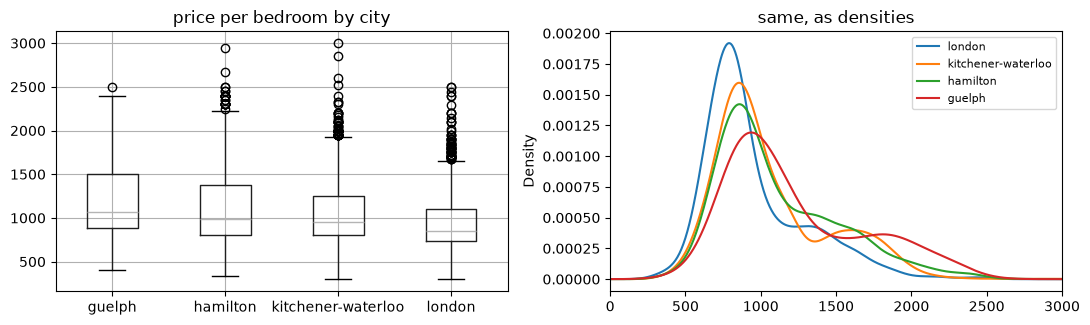

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
order = live.groupby("city")[TARGET].median().sort_values().index.tolist()
live.boxplot(column=TARGET, by="city", ax=axes[0])
axes[0].set_title("price per bedroom by city"); axes[0].set_xlabel("")
for c in order:
    live.loc[live["city"].eq(c), TARGET].plot.kde(ax=axes[1], label=c)
axes[1].set_xlim(0, 3000); axes[1].legend(fontsize=8); axes[1].set_title("same, as densities")
plt.suptitle(""); plt.tight_layout()

## 4. The transfer test

For each of 5 folds grouped by `dedup_key`: hold out a slice of **KW** rows, then train four
models and score all of them on that same held-out slice.

1. **KW only** — the KW training fold alone.
2. **+ other cities** — plus every Guelph, Hamilton and London row.
3. **+ archive** — plus every Wayback row.
4. **+ both**.

Grouping by `dedup_key` means no address appears in both train and test. If the extra rows
carry transferable signal, MAE goes down. If they mostly add noise or pull the fit toward a
different market, it goes up.

In [7]:
def kw_transfer(fit_predict, n_splits=5):
    """MAE on held-out KW rows for each of the four training sets."""
    kw = live[live["city"].eq(KW)].reset_index(drop=True)
    others = live[~live["city"].eq(KW)]
    names = ["KW only", "+ other cities", "+ archive", "+ both"]
    out = {k: [] for k in names}
    for tr, te in GroupKFold(n_splits=n_splits).split(kw, groups=kw[GROUP]):
        train, test = kw.iloc[tr], kw.iloc[te]
        y = test[TARGET].astype(float).to_numpy()
        sets = dict(zip(names, [
            train,
            pd.concat([train, others], ignore_index=True),
            pd.concat([train, archive], ignore_index=True),
            pd.concat([train, others, archive], ignore_index=True),
        ]))
        for name, t in sets.items():
            out[name].append(score(y, fit_predict(t, test)).mae)
    res = pd.DataFrame(out).agg(["mean", "std"]).T
    res.columns = ["MAE", "fold sd"]
    res["vs KW only"] = res["MAE"] - res.loc["KW only", "MAE"]
    res["train rows"] = [len(live[live["city"].eq(KW)]) * 4 // 5,
                         len(live) * 4 // 5 + len(live[~live["city"].eq(KW)]) // 5,
                         len(live[live["city"].eq(KW)]) * 4 // 5 + len(archive),
                         len(live) * 4 // 5 + len(archive)]
    return res.round(1)

ridge_transfer = kw_transfer(fit_predict_ridge)
ridge_transfer

,MAE,fold sd,vs KW only,train rows
KW only,142.0,4.8,0.0,2112
+ other cities,141.6,4.8,-0.4,6066
+ archive,164.3,5.2,22.3,11564
+ both,160.5,4.6,18.6,14728


In [8]:
lookup_transfer = kw_transfer(fit_predict_lookup)
lookup_transfer

,MAE,fold sd,vs KW only,train rows
KW only,159.1,4.7,0.0,2112
+ other cities,159.4,5.2,0.3,6066
+ archive,184.9,5.9,25.9,11564
+ both,183.0,5.9,24.0,14728


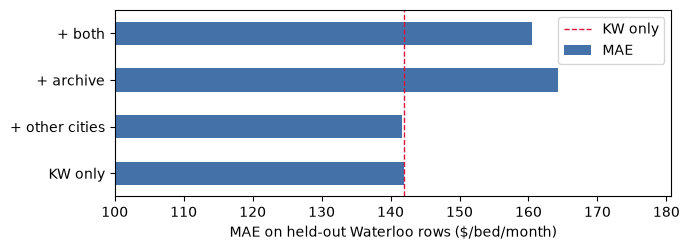

In [9]:
ax = ridge_transfer["MAE"].plot.barh(figsize=(7, 2.6), color="#4472a8")
ax.axvline(ridge_transfer.loc["KW only", "MAE"], color="crimson", ls="--", lw=1, label="KW only")
ax.set_xlabel("MAE on held-out Waterloo rows ($/bed/month)")
ax.set_xlim(100, ridge_transfer["MAE"].max() * 1.1); ax.legend(); plt.tight_layout()

## 5. Is the archive at least useful for the past?

The archive's value was never only row count — it is the only record of pre-2024 rents, which
is what a rent index would need. Check that the eras are actually populated before treating
`listing_year` as a usable feature.

In [10]:
era = pooled.groupby(["listing_year", pooled["is_archive"].astype("boolean").fillna(False)])[TARGET].agg(
    n="size", median="median").round(0).unstack(fill_value=0)
era.columns = [f"{'archive' if a else 'live'} {c}" for c, a in era.columns]
era

,live n,archive n,live median,archive median
listing_year,,,,
2014,0,1154,0.0,485.0
2015,0,1356,0.0,500.0
2016,0,1258,0.0,499.0
2017,0,1647,0.0,500.0
2018,0,83,0.0,575.0
2019,0,1,0.0,689.0
2020,0,74,0.0,680.0
2021,0,91,0.0,700.0
2022,0,154,0.0,900.0


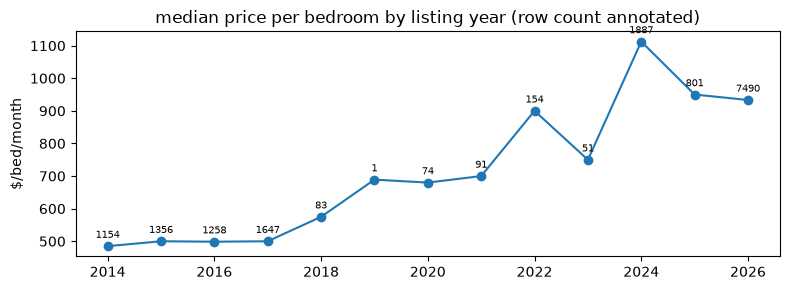

In [11]:
yearly = pooled.groupby("listing_year")[TARGET].agg(n="size", median="median")
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(yearly.index, yearly["median"], marker="o")
for x, (n, m) in yearly.iterrows():
    ax.annotate(int(n), (x, m), textcoords="offset points", xytext=(0, 6), fontsize=7, ha="center")
ax.set_title("median price per bedroom by listing year (row count annotated)")
ax.set_ylabel("$/bed/month"); plt.tight_layout()

## 6. Findings

**The table is mostly not Waterloo.** 60% of the 6,595 live rows are Guelph, Hamilton or
London, and with `--archive` on, Kitchener-Waterloo current listings are 2,641 of 16,047 rows
— **16%** of what the model trains on. For the other 84%, `walk_uw_min`, `walk_laurier_min`
and `ion_distance_m` are 100% NULL.

**The three extra cities are free but worthless.** Scored on held-out KW rows, adding all
3,954 of them moves ridge MAE by **−$0.4** (142.0 → 141.6) against a fold standard deviation
of $4.8. That is indistinguishable from zero. The lookup gets $0.3 *worse*. They cost nothing
in accuracy and buy nothing; they are tripling the scrape footprint for no measured gain.

**The Wayback archive actively hurts.** Adding it takes ridge from **$142.0 to $164.3**, a
**16% degradation**, far outside fold noise. The lookup degrades by $25.9. Section 5 shows why:
5,415 of 9,452 archive rows are 2014–2017 ads with a median of **~$500/bed**, against $933
for current listings. A single linear `listing_year` term cannot bridge a 2x level shift, so
pooling drags every current prediction downward.

**Why the 2026-11-06 decision read the opposite.** That entry recorded grouped CV improving
from $142 to $136 with `--archive`. It is not wrong, it is measuring a different thing: that
CV scores on a test set that is itself 59% archive rows, so the model is rewarded for
predicting decade-old rents well. Scored only on the population the app actually serves —
current Waterloo listings — the archive is a $22 liability. **The default must stay live-only,
and `--archive` should not be turned on for the shipping model.**

**What the archive is still for.** It is the only record of pre-2024 rents and the raw material
for a rent index (section 5's year curve is clean and monotonic apart from 2023 and 2025, both
thin). Deflating historical prices to today's dollars and *then* pooling is the experiment worth
running — not pooling raw. Until that exists, archive rows belong in the price-index work, not
in the training table.